# Phase 15: Regional Refiner Segmentation Loss Function Study

**Scientific Question:**
*Can alternative asymmetric loss functions (L1 Focal+Dice, L2 Tversky, L3 Focal Tversky) reduce false-positive regional background clutter while preserving tiny stone recall relative to the Phase-14 baseline loss (L0 BCE+Dice)?*

**Governance Notice:**
- **Current Status:** `PROTOCOL_FROZEN_AWAITING_SUPERVISOR_AUTHORIZATION`
- **Training of L1/L2/L3:** Strictly NOT authorized in this pre-training audit notebook.
- **Experimental Control (L0):** Fully evaluated from canonical Phase 14 artifacts.
- **Untouched TEST Set:** Strictly locked (`TEST reads = 0`, `TEST visualizations = 0`).


In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image

def find_root():
    p = Path.cwd()
    for _ in range(5):
        if (p / 'reports').exists() and (p / 'manifests').exists():
            return p
        p = p.parent
    return Path('D:/Softfors/jup')

ROOT = find_root()
print("Project Root:", ROOT)


Project Root: D:\Softfors\jup


## Section A: Loss Function Mathematical Formulations & Semantics

The Phase 15 prospective protocol freezes four loss formulations under identical architectures and data splits:

1. **L0: Balanced BCE + Soft Dice (Phase 14 Control)**
   $$\mathcal{L}_0 = 0.5 \cdot \mathcal{L}_{\text{BCE}}(z, y) + 0.5 \cdot \mathcal{L}_{\text{Dice}}(\sigma(z), y)$$
2. **L1: Binary Focal + Soft Dice**
   $$\mathcal{L}_1 = 0.5 \cdot \mathcal{L}_{\text{Focal}}(z, y; \alpha=0.25, \gamma=2.0) + 0.5 \cdot \mathcal{L}_{\text{Dice}}(\sigma(z), y)$$
3. **L2: Asymmetric Tversky Loss**
   $$\mathcal{L}_2 = 1.0 - \text{TI}(z, y; \alpha=0.30, \beta=0.70)$$
4. **L3: Focal Tversky Loss (High-Overlap Sensitivity)**
   $$\mathcal{L}_3 = (1.0 - \text{TI}(z, y; \alpha=0.30, \beta=0.70))^{0.75}$$
   $$\left| \frac{d\mathcal{L}_3}{d\text{TI}} \right| = \frac{0.75}{(1.0 - \text{TI})^{0.25}}$$


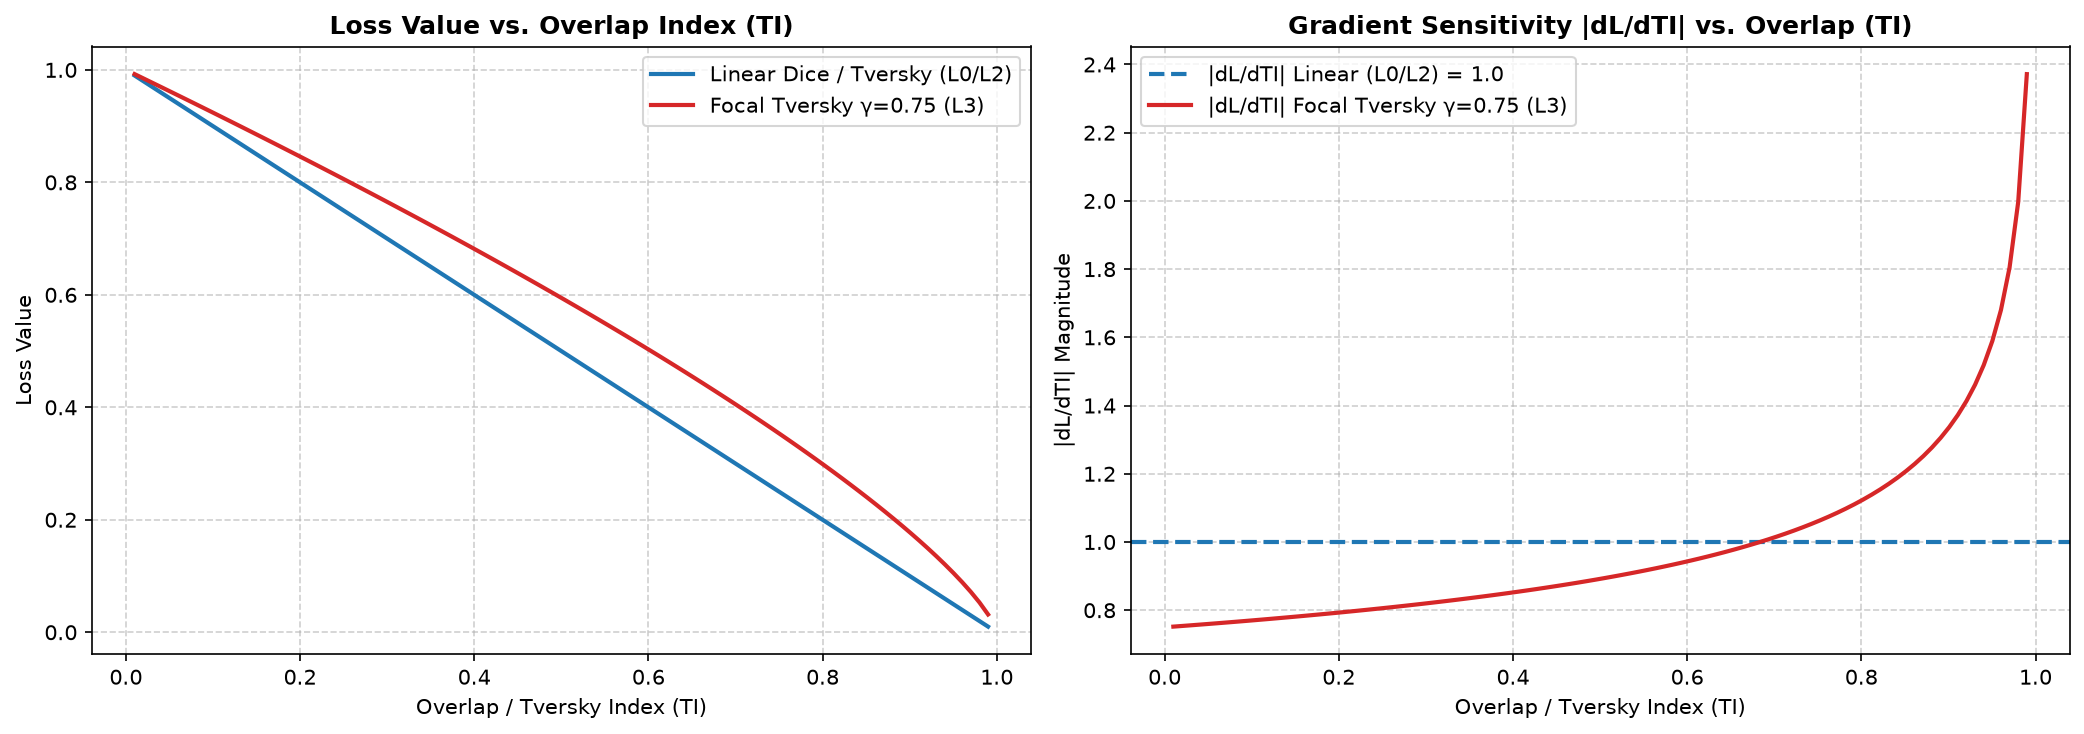

In [2]:
# Display pre-generated Loss & Derivative Sensitivity Figure
curve_path = ROOT / 'reports/figures/phase15_protocol/phase15_loss_derivatives_comparison.png'
if curve_path.exists():
    display(Image(filename=str(curve_path), width=900))
else:
    print("Curve figure not found at:", curve_path)


## Section B: Experimental Control (L0) Performance Baseline

L0 was executed under Phase 14 (`phase14_diag_regional_unet_oracletrain_a3_seed42_v1`, SHA-256 `89ada727...`). Below are the established historical metrics:


In [3]:
proto_path = ROOT / 'reports/audits/phase15_loss_study_protocol.json'
with open(proto_path, 'r', encoding='utf-8') as f:
    proto = json.load(f)

l0_summary = {
    "Metric": [
        "Loss Formulation",
        "Best Checkpoint Epoch",
        "VAL Crop Macro Dice",
        "Oracle FULL_FIELD Dice",
        "Predicted FULL_FIELD Dice (Dp)",
        "Oracle Tiny Recall",
        "Predicted Tiny Recall (Tp)",
        "Minimum Required Dp for Candidates",
        "Minimum Required Tiny Recall (Tp)"
    ],
    "L0 Value / Threshold": [
        "0.5 BCE + 0.5 SoftDice",
        "Epoch 14",
        "0.8437",
        "0.8152",
        "0.3839",
        "73 / 73 (1.000)",
        "65 / 73 (0.8904)",
        ">= 0.3739",
        ">= 62 / 73 (0.8493)"
    ]
}
df_l0 = pd.DataFrame(l0_summary)
display(df_l0)


,Metric,L0 Value / Threshold
0,Loss Formulation,0.5 BCE + 0.5 SoftDice
1,Best Checkpoint Epoch,Epoch 14
2,VAL Crop Macro Dice,0.8437
3,Oracle FULL_FIELD Dice,0.8152
4,Predicted FULL_FIELD Dice (Dp),0.3839
5,Oracle Tiny Recall,73 / 73 (1.000)
6,Predicted Tiny Recall (Tp),65 / 73 (0.8904)
7,Minimum Required Dp for Candidates,>= 0.3739
8,Minimum Required Tiny Recall (Tp),>= 62 / 73 (0.8493)


## Section C: 16 Deterministic Case Predictions (Baseline Control)

Below are representative panels from the 16 deterministic validation cases evaluated under the baseline pipeline.


Verified 16 deterministic evaluation panels:


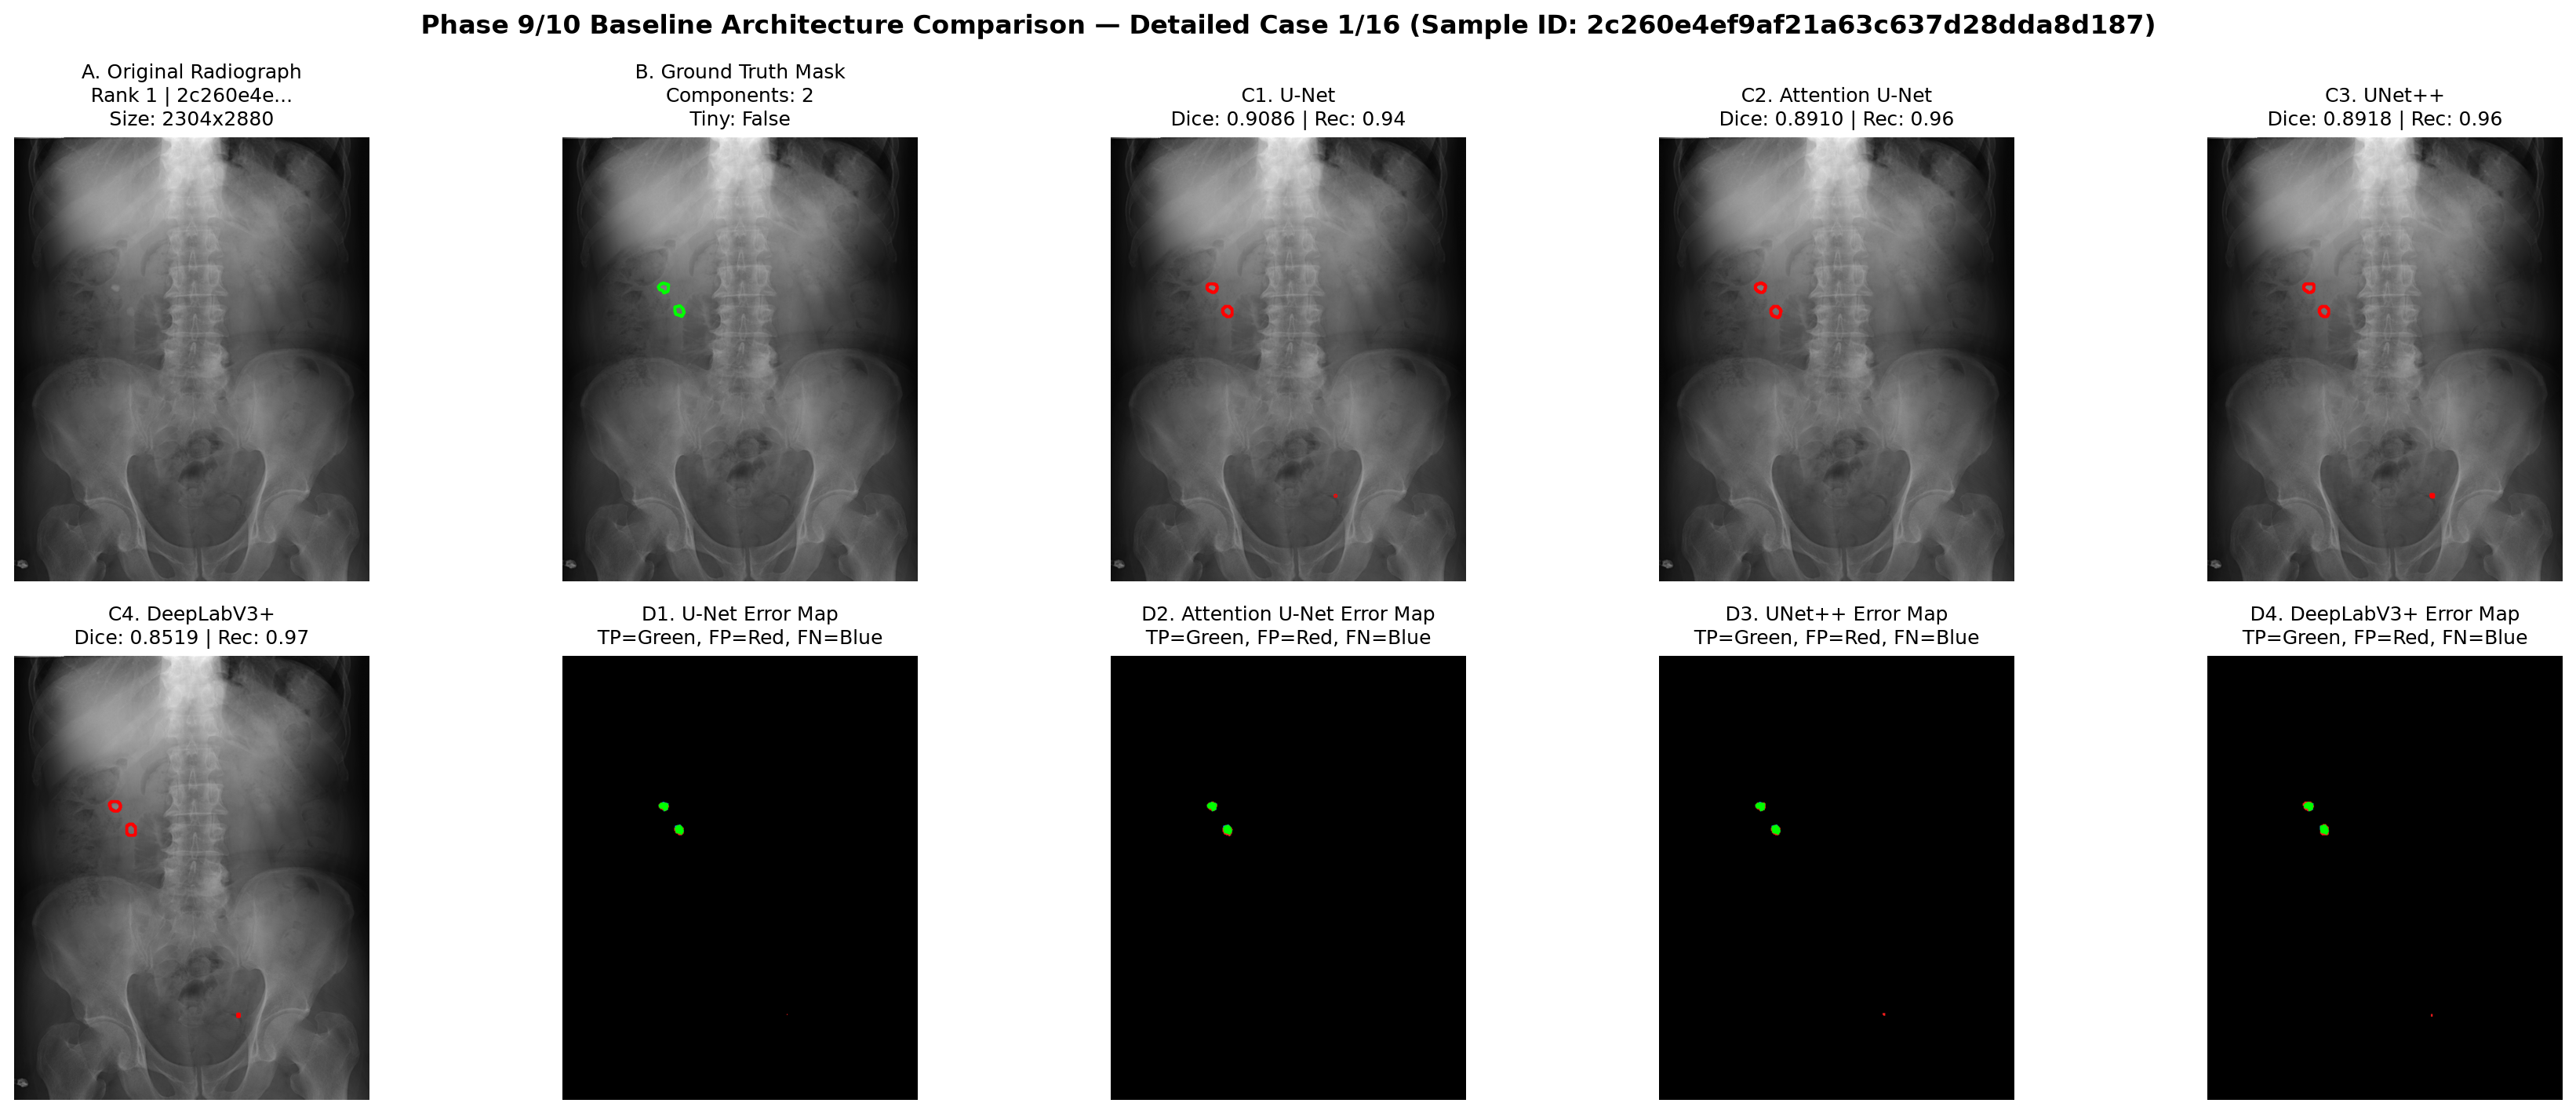

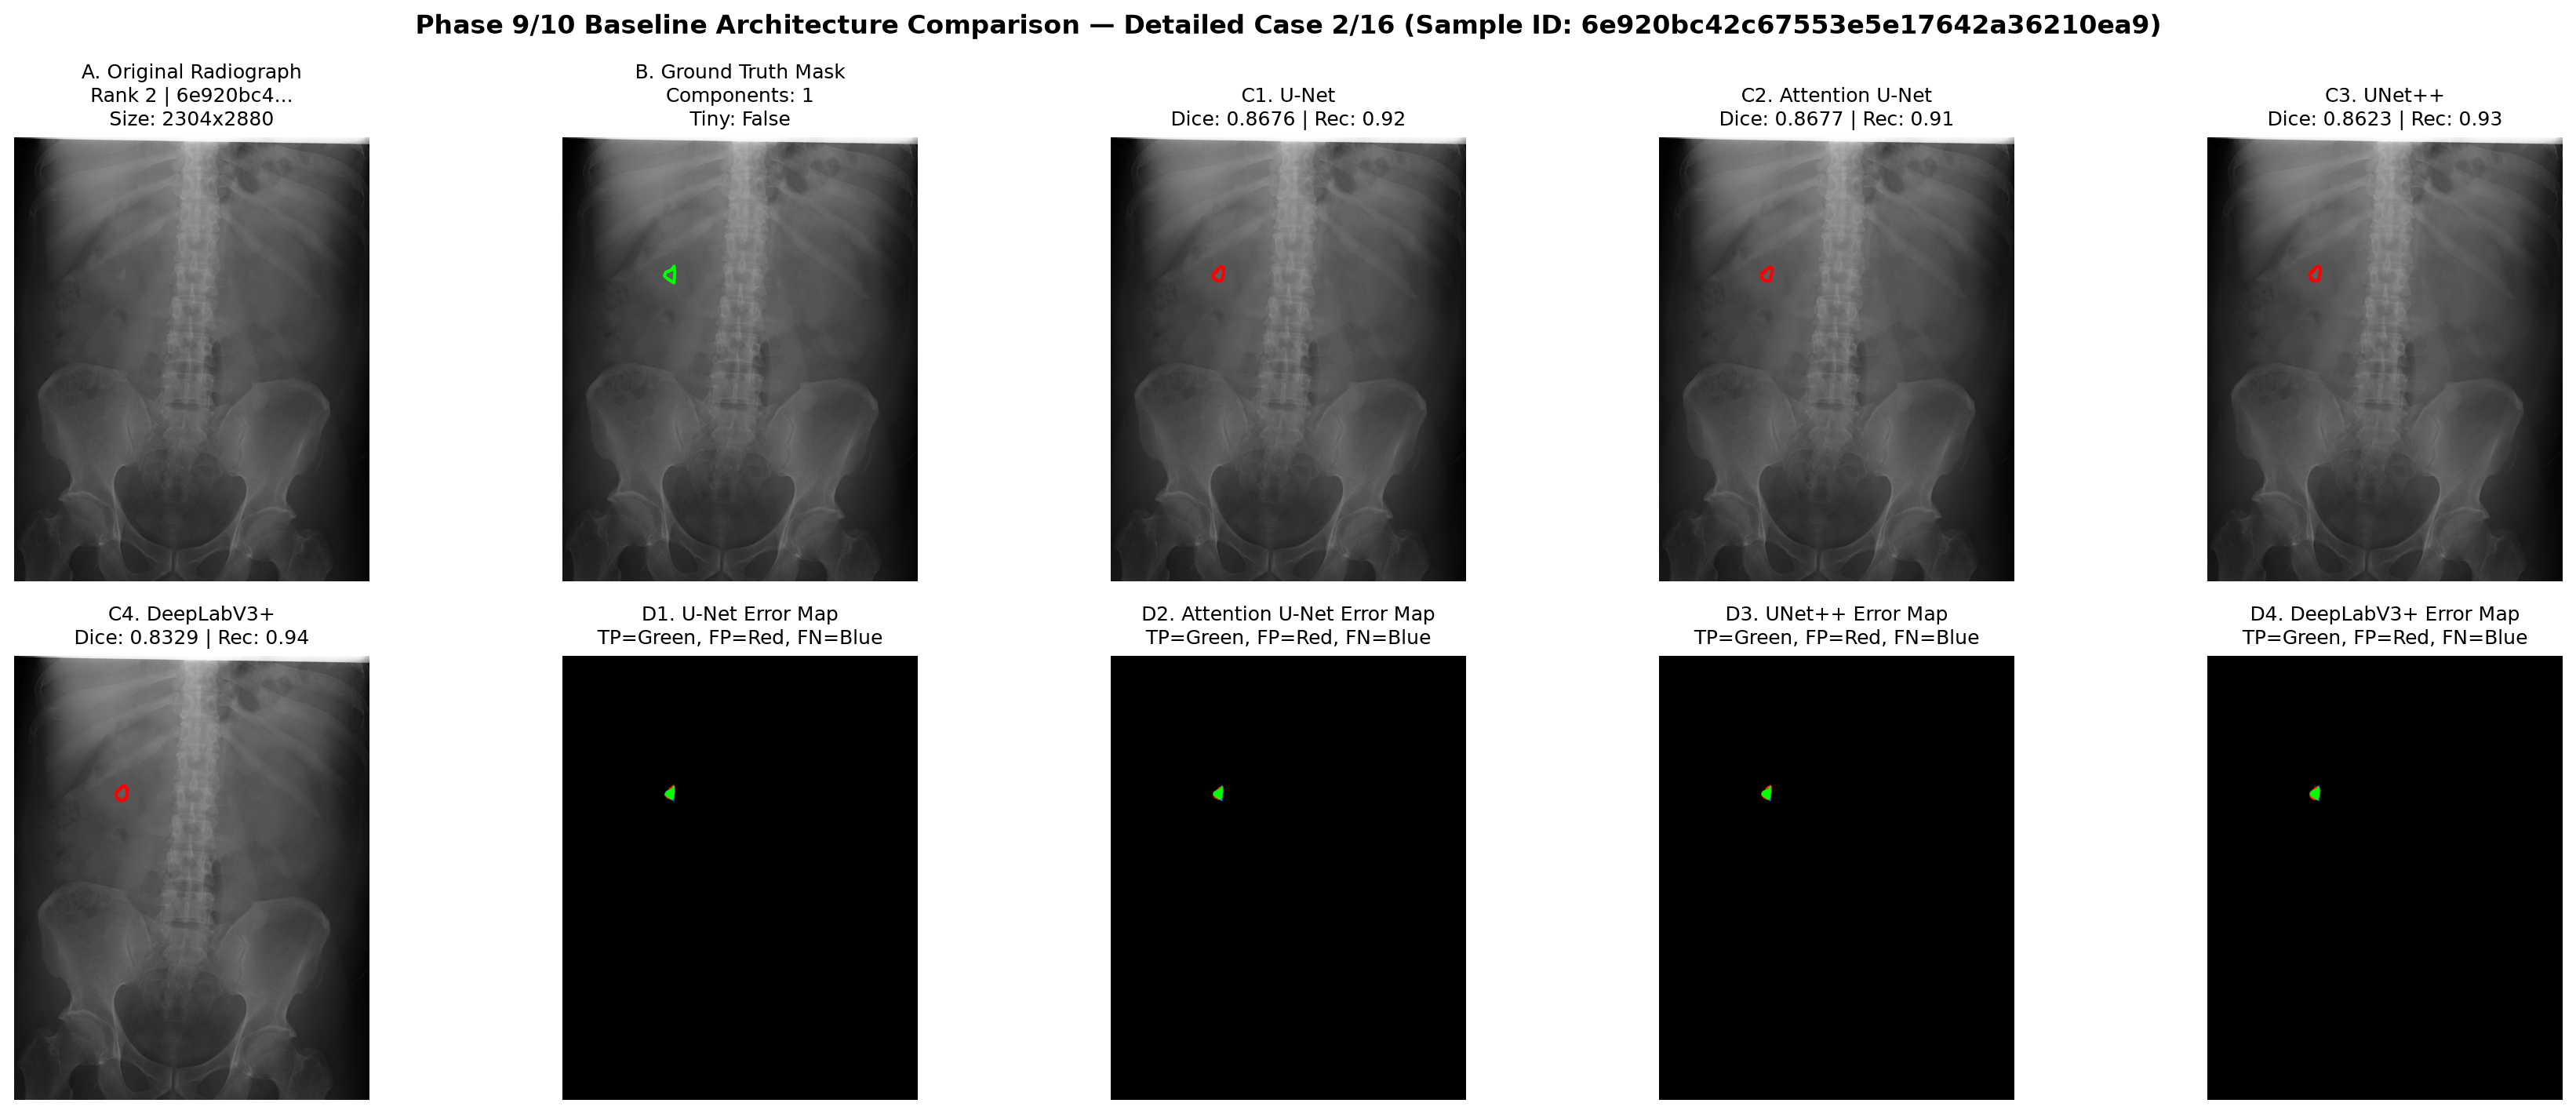

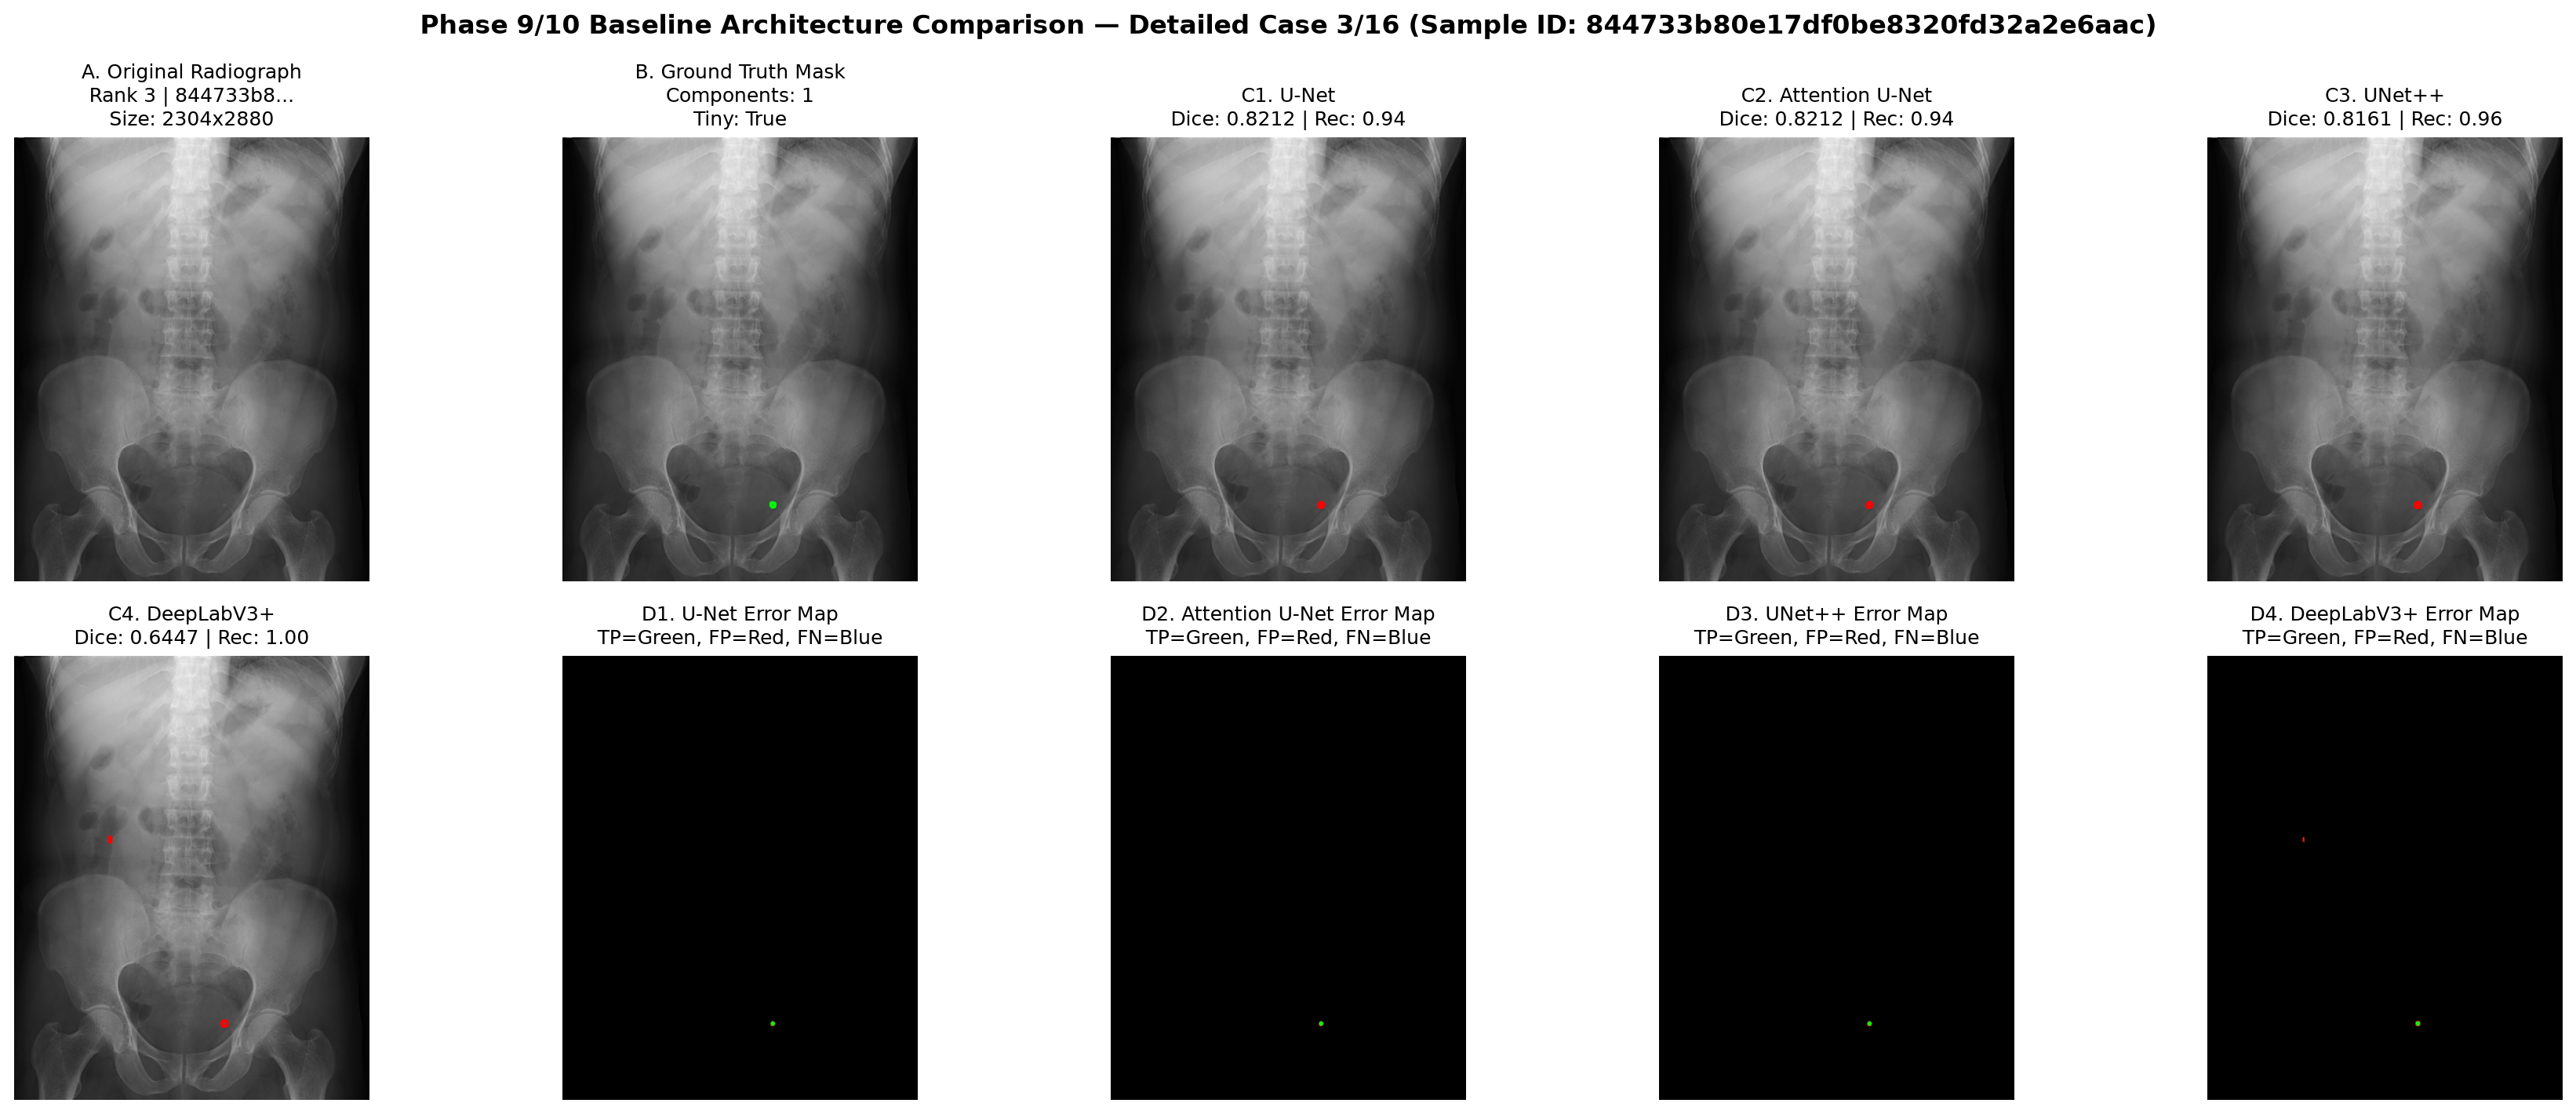

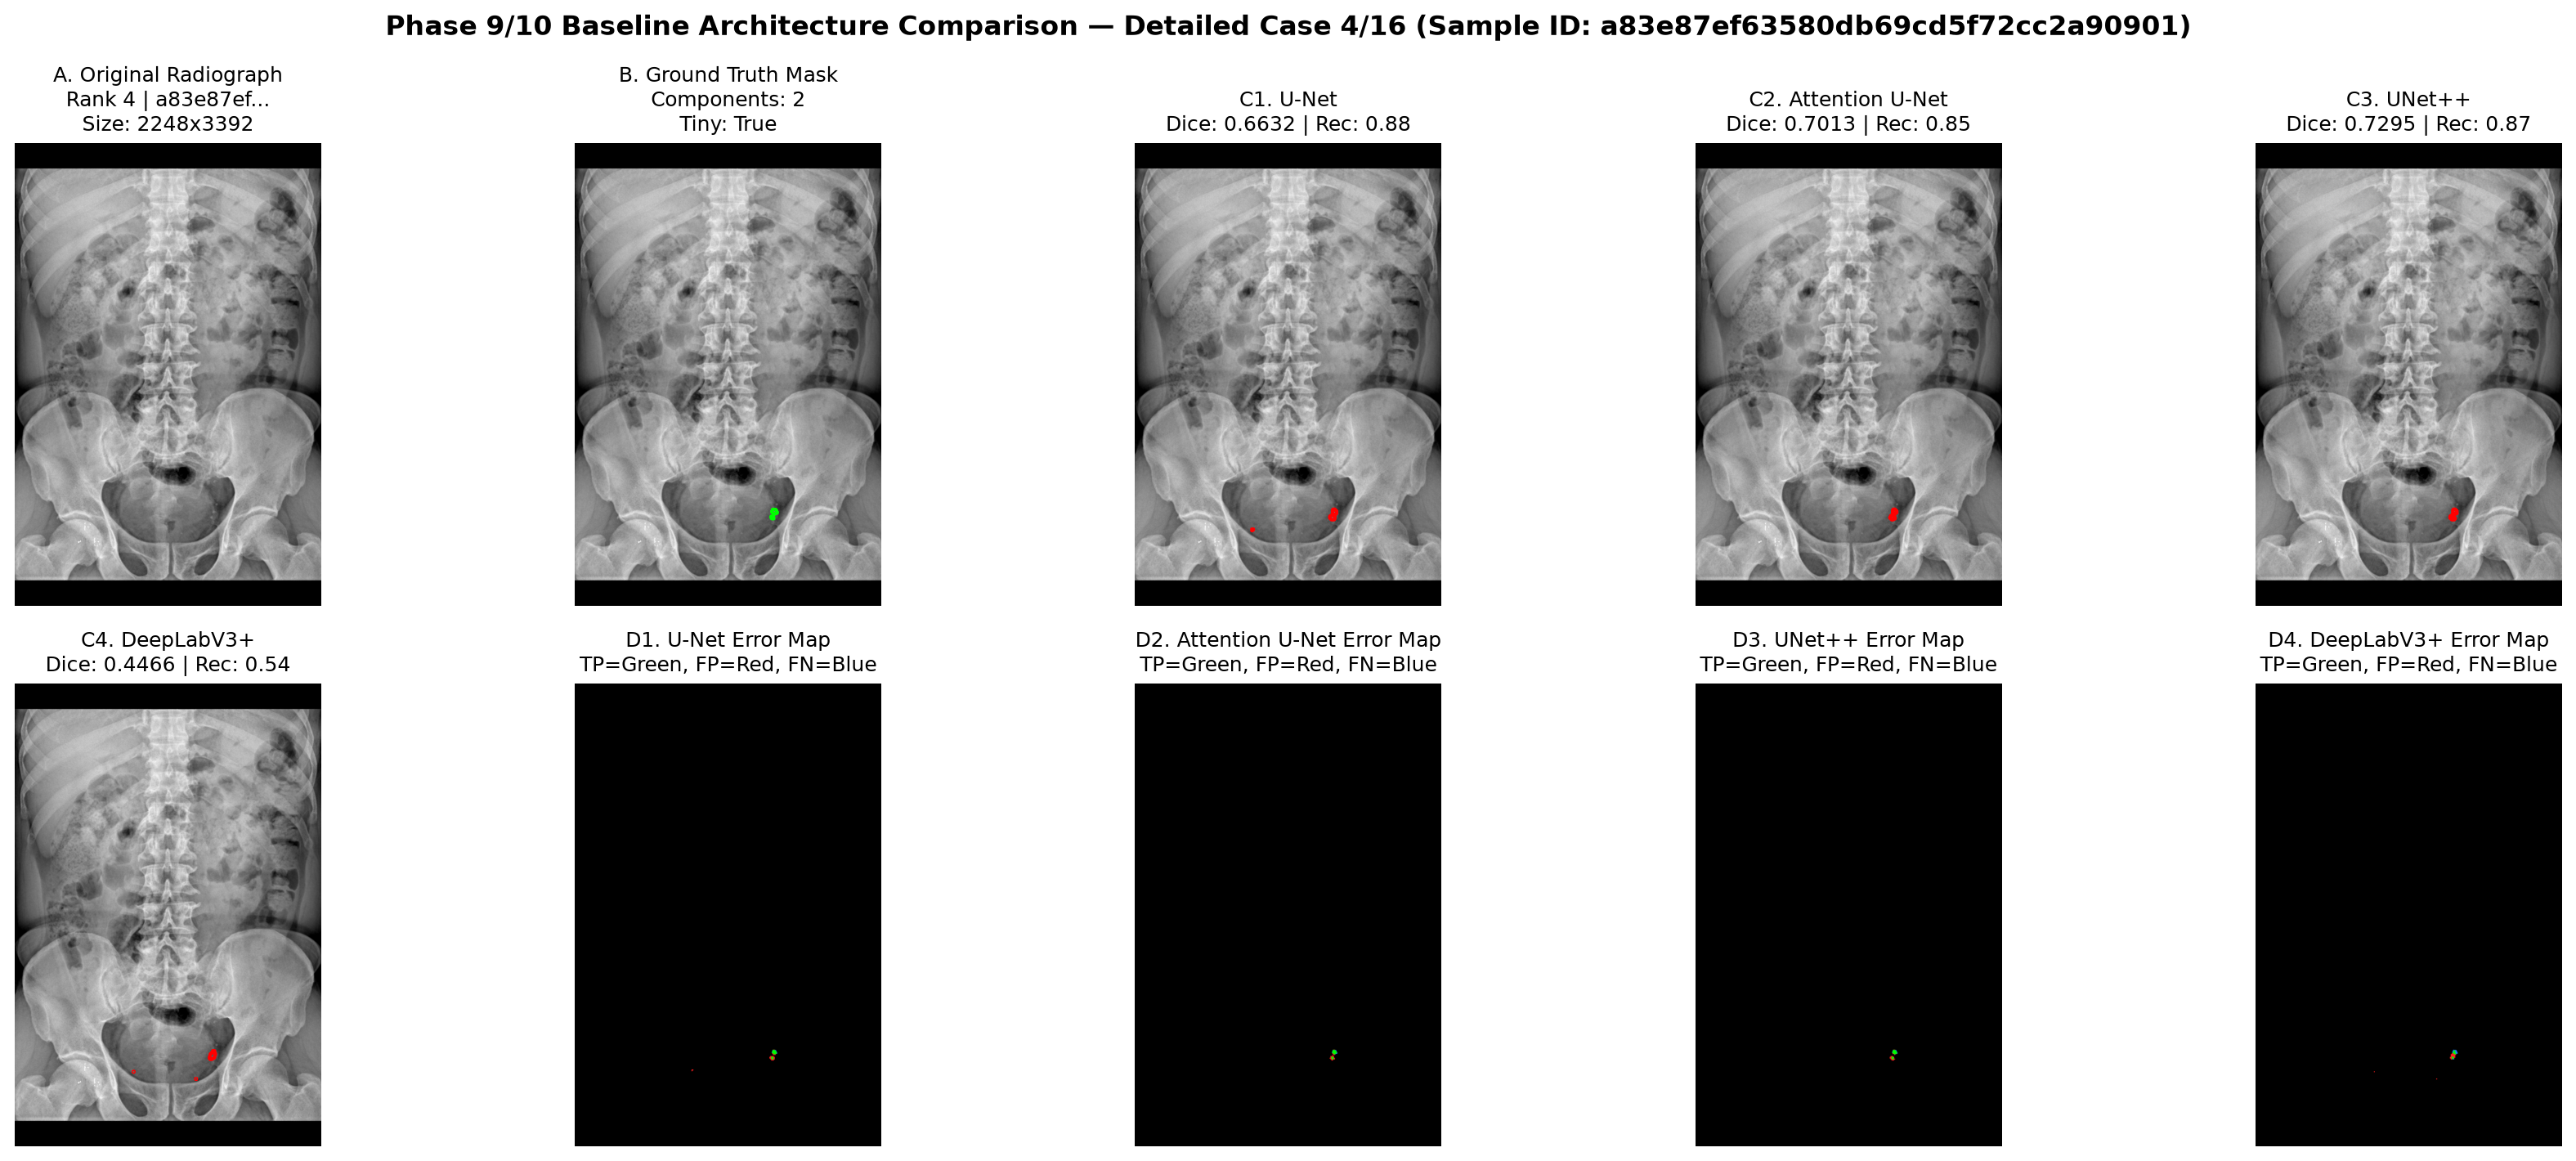

... and 12 additional deterministic validation panels recorded in reports/figures/retrospective/phase10_baselines/


In [4]:
import glob
panels = sorted(glob.glob(str(ROOT / 'reports/figures/retrospective/phase10_baselines/case_*.png')))[:16]
print(f"Verified {len(panels)} deterministic evaluation panels:")
for p in panels[:4]:
    display(Image(filename=p, width=800))
print(f"... and {len(panels)-4} additional deterministic validation panels recorded in reports/figures/retrospective/phase10_baselines/")


## Section D: Predefined Decision Rules & Governance Closure

### Success Rule for Candidate Losses (L1, L2, L3)
1. **Primary Crop Gain:** $\text{Val Crop Dice}(L_k) \ge 0.8537$ OR $\text{Tiny Crop Dice}(L_k) \ge \text{Tiny}(L_0) + 0.020$.
2. **Secondary Stability Constraints:**
   - Full-field predicted Dice: $D_p(L_k) \ge 0.3739$.
   - Tiny stone detection recall: $T_p(L_k) \ge 62 / 73$ ($0.8493$).

### Deterministic Selection Hierarchy
- If multiple candidates pass, selection proceeds by: (1) Val Crop Dice $\to$ (2) Tiny Crop Dice $\to$ (3) Full-Field $D_p$ $\to$ (4) FP component rate.
- If zero candidates pass, L0 is scientifically retained with zero penalty.

### Scientific Integrity & Audit Status
- **L1/L2/L3 Training Status:** `BLOCKED_AWAITING_SUPERVISOR_AUTHORIZATION`
- **Zero Fake Results Guarantee:** No prospective numbers are invented for L1-L3.
- **Untouched Test Barrier:** Strictly maintained (`TEST reads = 0`).
